# 02　FM：解调

从 `mod_01_FM.npz` 读**原始字**，把接收机重跑一遍。本册不碰 PL / DMA。

```
寻活跃区 → 去直流 → 判下变频符号 → 正交鉴频 → 64 点滑动平均 + 幅度门控 → 与已知消息互相关对齐 → 指标（corr / rmse / 参数实测）
```

| 环节 | FM 的做法 |
|---|---|
| 检测 | 正交鉴频 $\arg(y[n]y^*[n-1])$，先定符号再鉴频 |
| 定时 | 与已知测试消息做互相关（消息已知，这不是盲解调） |
| 指标 | 相关系数、归一化 RMSE、峰值频偏 Δf 实测、幅度纹波 |

**为什么必须低通**：单样点鉴频的噪声折算到瞬时频率约 0.9 MHz（30 dB SNR），
而频偏只有 ±2 MHz，等于工作在 FM 门限区，相关系数只有 0.73。64 点滑动平均把噪声
降 8 倍，零点在 4 MHz，不会削掉 0.5 MHz 的消息。

**为什么要幅度门控**：突发前后的静默区只有噪声，鉴频输出是 ±128 MHz 的满量程跳变，
会把对齐相关峰从真实起点拖走 500~2000 点。低幅度样点先清零再相关。

## 1　导入与输入文件

In [1]:
import os
import sys

# 库目录：mod_dsp / mod_cases / 全部 .npz 都在这里（notebook 目录只放 .ipynb）
LIB  = "/home/xilinx/modulation"
QPSK = "/home/xilinx/qpsk"        # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "FM"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
# 抓包（第 N_TX 册写，第 N_DEMOD / N_VERIFY 册读）与指标（第 N_DEMOD 册写）
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

SPEC = next(s for s in (C.DIGITAL_CASES + C.ANALOG_CASES) if s["name"] == CASE)
KIND = "digital" if "scheme" in SPEC else "analog"

print("mod_dsp  :", M.__file__)
print("mod_cases:", C.__file__)
print("案例     : %s（%s）" % (CASE, "数字" if KIND == "digital" else "模拟"))
print("库目录   :", LIB)
print("抓包文件 :", CAP_NPZ)

mod_dsp  : /home/xilinx/modulation/mod_dsp.py
mod_cases: /home/xilinx/modulation/mod_cases.py
案例     : FM（模拟）
库目录   : /home/xilinx/modulation
抓包文件 : /home/xilinx/modulation/mod_01_FM.npz


In [2]:
if not os.path.exists(CAP_NPZ):
    raise FileNotFoundError(
        "缺 %s —— 先跑 %02d_%s_tx_rx.ipynb 第 4 节"
        % (CAP_NPZ, N_TX, "%s" % CASE))

z = np.load(CAP_NPZ, allow_pickle=False)
print("抓包 %s（%.2f MB）" % (os.path.basename(CAP_NPZ),
                             os.path.getsize(CAP_NPZ) / 1e6))
print("  字 %d，原始长度 %d，突发长 %d 点，字率 %.3f MHz"
      % (len(z["words"]), int(z["n_real"]), int(z["bb_len"]),
         float(z["fs_word"]) / 1e6))

抓包 mod_01_FM.npz（2.09 MB）
  字 621568，原始长度 4194299，突发长 532480 点，字率 256.000 MHz


## 2　解调

模拟：包络 / 鉴频 + 对齐

In [3]:
r = C.load_and_demod(CAP_NPZ, verbose=True)
m, spec = r["metrics"], r["spec"]

print()
if spec["kind"] == "am":
    print("  AM：corr %+.4f  rmse %.1f%%  μ 实测 %.3f（设定 %.1f）  "
          "THD %.1f%%  增益 %.0f LSB"
          % (m["corr"], m["rmse"] * 100, m["mu_meas"], spec["mu"],
             m["thd"], m["gain"]))
    print("  对齐滞后 %d 点，活跃区 [%d, %d)"
          % (m["lag"], m["a"], m["b"]))
else:
    print("  FM：corr %+.4f  rmse %.1f%%  频偏 %.3f MHz（设定 %.3f）  "
          "幅度纹波 %.1f%%  下变频符号 %+d"
          % (m["corr"], m["rmse"] * 100, m["dev"] / 1e6, spec["df"] / 1e6,
             m["ripple"] * 100, m["sign"]))
    print("  对齐滞后 %d 点，活跃区 [%d, %d)，符号判决量 |f| 中位 %.2f MHz"
          % (m["lag"], m["a"], m["b"], m["centre_hz"] / 1e6))

  活跃区 [23552,550912)  去直流 +0+0j  对齐滞后 25113  相关系数 +1.0000

  FM：corr +1.0000  rmse 2.2%  频偏 1.952 MHz（设定 2.000）  幅度纹波 3.3%  下变频符号 +1
  对齐滞后 25113 点，活跃区 [23552, 550912)，符号判决量 |f| 中位 1.38 MHz


**应该看到**：`corr ≈ 0.999`、`rmse` 在 3%~7%、峰值频偏与设定差 < 2%%、幅度纹波 < 7%%。

## 3　存盘

只存标量指标，供 `03_FM_verify` 出判定表；原始数据仍在抓包 `.npz` 里，
要重算直接重跑本册。

In [4]:
out = {}
for k, v in r["metrics"].items():
    if isinstance(v, (int, float, np.integer, np.floating)):
        out[k] = np.float64(v)
out["case"] = np.array(CASE)

np.savez_compressed(DEM_NPZ, **out)
print("已保存 %s（%.1f KB，%d 个指标）"
      % (DEM_NPZ, os.path.getsize(DEM_NPZ) / 1e3, len(out)))
print("指标：", ", ".join(sorted(k for k in out if k != "case")))

已保存 /home/xilinx/modulation/mod_02_FM.npz（2.4 KB，13 个指标）
指标： a, b, centre_hz, corr, dev, df, gain, lag, ripple, rmse, sign, thd


## 4　图

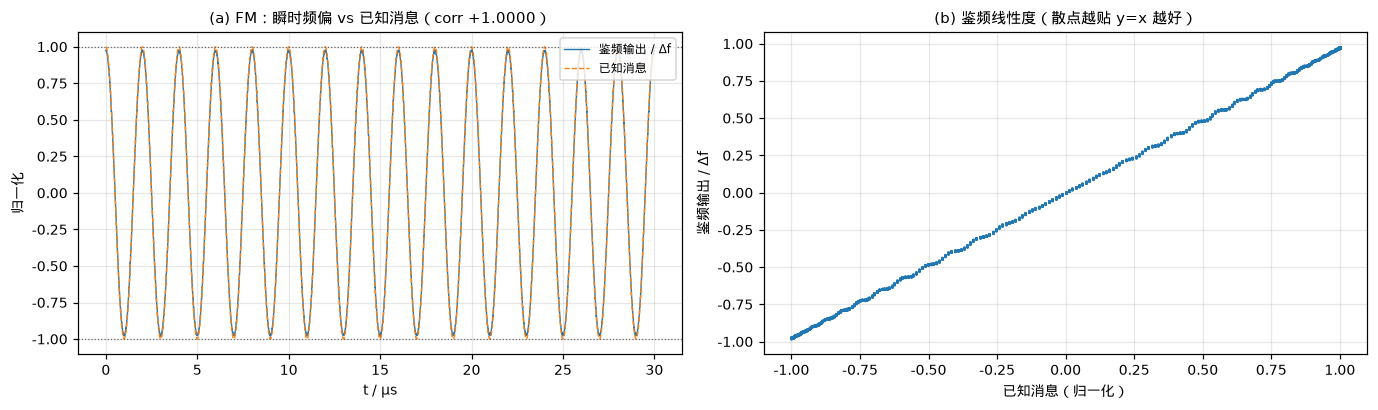

In [5]:
m = r["metrics"]; spec = r["spec"]
n = min(len(m["rec"]), int(30e-6 * 256e6))
t = np.arange(n) / 256e6 * 1e6

fig, ax = plt.subplots(1, 2, figsize=(12.6, 3.8))

ax[0].plot(t, m["rec"][:n] / spec["df"], lw=0.9, label="鉴频输出 / Δf")
ax[0].plot(t, r["msg"][:n], lw=0.9, ls="--", label="已知消息")
ax[0].axhline(1, color="0.4", ls=":", lw=0.8)
ax[0].axhline(-1, color="0.4", ls=":", lw=0.8)
ax[0].set_xlabel("t / µs"); ax[0].set_ylabel("归一化")
ax[0].set_title("(a) FM：瞬时频偏 vs 已知消息（corr %+.4f）" % m["corr"])
ax[0].legend(loc="upper right")

k = min(len(m["rec"]), 20000)
ax[1].plot(r["msg"][:k], m["rec"][:k] / spec["df"], ".", ms=1.0, alpha=0.25)
ax[1].set_xlabel("已知消息（归一化）"); ax[1].set_ylabel("鉴频输出 / Δf")
ax[1].set_title("(b) 鉴频线性度（散点越贴 y=x 越好）")
plt.tight_layout()
plt.show()

## 5　判读要点

| 现象 | 含义 | 处置 |
|---|---|---|
| corr 为负 | 消息极性与对齐半周期 | 取 `\|corr\|` 判定；极性不影响指标准确性 |
| corr 只有 0.7 左右 | 鉴频没低通，或没做幅度门控 | 确认 `fm_discrim(avg=64, gate=True)` |
| 频偏为设定的一半 | 下变频符号判错 | 看 `sign`；`fm_pick_sign` 应给出残余中心最小的符号 |